# Geo-test pre-launch checks

Three checks to run on **your own** geo-level sales history before you launch a geo test:

1. **Comparison strength.** Does the control track the test geos? This uses daily and weekly correlation, the MAPE of the scaled control, and a short out-of-sample dry run.
2. **Required spend.** What does it cost to detect the lift you care about?
3. **Can the business act?** Will anyone act on the result?

The notebook ends with a verdict: **GO**, **FIX**, or **DON'T TEST**.

Full write-up (the guide is coming): https://brinkeranalytics.com/insights/before-you-call-a-geo-test-feasible

> **About the numbers.** This notebook runs on synthetic data: 20 fictional DMAs and no client data. The MDE, required spend and verdict are computed from the data you load. Values you type in are labeled **EXAMPLE**: test length, planned change, target iROAS, margin, budgets and checklist answers. Replace them with your own. Nothing here is a benchmark.

## 0. Setup and data load

The input is a GA4-style CSV export of sales by date by DMA, and the notebook works from that file alone, with no connection to GA4. The loader auto-detects common GA4 column names (`Date`; `DMA`, `Region` or `City`; `Purchase revenue`, `Total revenue` or `Transactions`), skips export comment lines and `Grand total` rows, and drops `(not set)` geos with a report. Missing days stay missing: they are reported, never silently treated as zero sales. To use your own data, change `DATA_PATH`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from geo_pretest import (load_ga4_csv, to_wide, comparison_strength, dry_run, required_spend,
                         DecisionChecklist, evaluate_checklist, verdict, power, Z_ONE_SIDED_90_CONF_80_POWER)

DATA_PATH = ROOT / "data" / "synthetic_ga4_sales_by_dma.csv"   # SYNTHETIC sample; replace with your export
sales = load_ga4_csv(DATA_PATH)          # columns auto-detected; pass date_col/geo_col/sales_col to override
wide = to_wide(sales)                    # missing days stay NaN; to_wide(sales, fill_missing="zero") only if you mean it
print("Load report:", sales.attrs["load_report"])
print("Days missing per geo:", wide.attrs["gaps"] or "none")
print(f"{wide.shape[1]} geos, {len(wide)} days: {wide.index.min().date()} to {wide.index.max().date()}")
wide.tail(3).round(0)

Load report: {'date_col': 'Date', 'geo_col': 'DMA', 'sales_col': 'Purchase revenue', 'rows_read': 9100, 'total_rows_dropped': 0, 'not_set_rows_dropped': 0, 'not_set_sales_dropped': 0.0, 'rows_used': 9100}
Days missing per geo: none
20 geos, 455 days: 2025-01-01 to 2026-03-31


geo,Example DMA 01,Example DMA 02,Example DMA 03,Example DMA 04,Example DMA 05,Example DMA 06,Example DMA 07,Example DMA 08,Example DMA 09,Example DMA 10,Example DMA 11,Example DMA 12,Example DMA 13,Example DMA 14,Example DMA 15,Example DMA 16,Example DMA 17,Example DMA 18,Example DMA 19,Example DMA 20
date,,,,,,,,,,,,,,,,,,,,
2026-03-29,7409.0,6755.0,5124.0,3425.0,2333.0,2119.0,31030.0,4924.0,2764.0,1386.0,10516.0,2939.0,4675.0,2503.0,7075.0,4595.0,4213.0,18576.0,627.0,6355.0
2026-03-30,7125.0,6161.0,4289.0,3112.0,2207.0,1756.0,26850.0,3814.0,2335.0,1123.0,7816.0,2575.0,4366.0,1824.0,5347.0,4422.0,3733.0,15909.0,392.0,4115.0
2026-03-31,7475.0,5832.0,4546.0,2897.0,2104.0,1976.0,26977.0,4180.0,2797.0,1163.0,8334.0,2687.0,3852.0,1961.0,4915.0,4552.0,3376.0,17384.0,502.0,5217.0


## 1. Choose the test and control geos, and your assumptions

You list the geos yourself; version 1 does no automatic market search. Use one or two controls. Combine several test geos into one cell if needed.

Every value below is an **EXAMPLE assumption** for the synthetic data. Replace each with your own.

In [2]:
TEST_GEOS    = ["Example DMA 03", "Example DMA 08"]   # EXAMPLE
CONTROL_GEOS = ["Example DMA 05", "Example DMA 12"]   # EXAMPLE (1-2 controls)

TEST_DAYS          = 84       # EXAMPLE planned test length (12 weeks, whole weeks only). Your choice, not a recommendation.
PLANNED_CHANGE     = 0.15     # EXAMPLE lift you plan to create (15%)
TARGET_IROAS       = 2.5      # EXAMPLE revenue-basis target iROAS (2.5x)
GROSS_MARGIN       = 0.55     # EXAMPLE gross margin, used for the breakeven iROAS
DESIGN             = "holdout"  # "holdout" (turn spend off in test geos) or "heavy-up" (extra spend)
SPEND_IN_TEST_GEOS = 30_000   # EXAMPLE spend you would turn off (holdout) or add (heavy-up) in the test geos over the window
CURRENT_SPEND      = None     # EXAMPLE current spend in the test geos over the window (heavy-up sanity check)
COMFORT_BUDGET     = 25_000   # EXAMPLE leadership's comfort-zone budget for the test

## 2. Check 1: comparison strength

The thresholds are "how I read it" guidance, not rules:

- **Correlation:** above 90%, preferably above 95%. Checked on daily and weekly data over the full history and over the most recent ~2x test length. Weekly correlation must not be weak; if it is, choose different controls. If daily is weak but weekly is OK, the check passes: read the test weekly and plan a longer test, using the recommended length from the power score (Check 2).
- **MAPE of the scaled control (weekly):** under 10% strong, 10-15% acceptable, 15-20% caution, over 20% weak. Caution is not a failure, but the MDE will be higher and the result less certain. Zero-sales days are left out of MAPE and counted; WAPE is shown alongside. The scale factor comes from a period at least as long as the test.
- **History:** at least as long as the test. Ideally it covers a year that includes a seasonal peak.

In [3]:
comp = comparison_strength(wide, TEST_GEOS, CONTROL_GEOS, TEST_DAYS)
pd.DataFrame({
    "value": [f"{comp.corr_daily:.1%}", f"{comp.corr_weekly:.1%}",
              f"{comp.corr_daily_recent:.1%}", f"{comp.corr_weekly_recent:.1%}",
              f"{comp.mape_daily:.1%}", f"{comp.mape_weekly:.1%}", f"{comp.wape_weekly:.1%}",
              f"{comp.scale_factor:.3f} (from last {comp.scale_days} days)", f"{comp.history_days} days"],
    "read as": [comp.corr_daily_band, comp.corr_weekly_band, f"last {comp.recent_days} days", f"last {comp.recent_days} days",
                "(daily, for reference)", comp.mape_weekly_band, "(weekly, for reference)",
                "", "covers test" if comp.history_covers_test else "SHORTER THAN TEST"],
}, index=["Correlation, daily", "Correlation, weekly", "Correlation, daily (recent)", "Correlation, weekly (recent)",
          "MAPE scaled control, daily", "MAPE scaled control, weekly", "WAPE scaled control, weekly",
          "Scale factor", "History"])

,value,read as
"Correlation, daily",84.9%,weak
"Correlation, weekly",93.5%,acceptable
"Correlation, daily (recent)",88.4%,last 168 days
"Correlation, weekly (recent)",96.4%,last 168 days
"MAPE scaled control, daily",6.6%,"(daily, for reference)"
"MAPE scaled control, weekly",2.5%,strong
"WAPE scaled control, weekly",2.5%,"(weekly, for reference)"
Scale factor,1.823 (from last 84 days),
History,455 days,covers test


- Correlation passes on weekly data only: read the test weekly and use the recommended length from the power score.


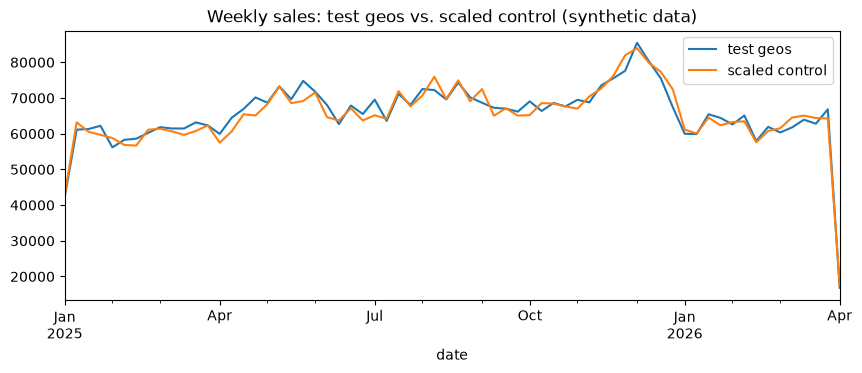

In [4]:
for n in comp.notes: print("-", n)
treat = wide[TEST_GEOS].sum(axis=1, min_count=len(TEST_GEOS))
ctrl = wide[CONTROL_GEOS].sum(axis=1, min_count=len(CONTROL_GEOS)) * comp.scale_factor
ax = treat.resample("W-SUN").sum().plot(figsize=(10, 3.5), label="test geos")
(ctrl.resample("W-SUN").sum()).plot(ax=ax, label="scaled control")
ax.set_title("Weekly sales: test geos vs. scaled control (synthetic data)"); ax.legend(); plt.show()

### Short-form dry run (out of sample)

The dry run holds back a final window about as long as the test (at least two weeks). The scale factor and the noise model are estimated on the earlier pre-period only, then the comparison predicts the held-back window. Nothing changed during that window, so it should show about zero lift.

The dry run passes only if both are true:
- the placebo lift is smaller than the MDE (in absolute value), and
- the 90% interval around the placebo lift (using the corrected standard error) includes zero.

In [5]:
dry = dry_run(wide, TEST_GEOS, CONTROL_GEOS, TEST_DAYS)
print(f"Holdout window: {dry.holdout_start.date()} to {dry.holdout_end.date()} ({dry.holdout_days} days)")
print(f"Placebo lift: {dry.placebo_lift:+.1%}  (90% interval {dry.interval_low:+.1%} to {dry.interval_high:+.1%})")
print(f"|Placebo| below the MDE ({dry.mde:.1%}, from the pre-period): {dry.placebo_below_mde}; interval includes zero: {dry.interval_includes_zero}")
print("Dry run:", "PASS" if dry.passes else "FAIL")
for n in dry.notes: print("-", n)

Holdout window: 2026-01-07 to 2026-03-31 (84 days)
Placebo lift: +0.9%  (90% interval -1.5% to +3.3%)
|Placebo| below the MDE (3.1%, from the pre-period): True; interval includes zero: True
Dry run: PASS


## 3. Check 2: required spend and power

**Required spend = MDE × baseline treatment sales over the test window ÷ target iROAS**

- **MDE:** computed from your own noise at 90% confidence, 80% power, one-sided. The noise is the out-of-sample weekly % error of the scaled control (rolling windows). The MDE is reported as a **range**, and decisions use the upper end. The standard error includes the scale-factor estimation error, `se = sd × sqrt(7/test_days + 7/scale_days)`, dependence between weeks (lag-1 autocorrelation or the long-run SD, whichever is larger) and a small-sample correction. That corrected estimate is cross-checked against empirical fake tests in your history (when it is at least 2x the test length) and against same-season error (when you have a year). Without either cross-check, the upper end equals the corrected estimate.
- **Power score:** the chance the test detects your planned change, `Phi(change / se − z)`. If it is under 80%, you get a recommended length in whole weeks.
- **Baseline treatment sales:** the test geos' recent run rate × the test length.
- **Holdout (decrease):** the baseline is the recent run rate with the spend still on, so it includes the sales driven by the spend you turn off; that spend × iROAS must create a gap of at least MDE × baseline.
- **Heavy-up (increase):** the result is extra spend on top of business as usual, sanity-checked against current spend.
- **iROAS:** the target is on a revenue basis. It's compared with the margin-based breakeven iROAS (1 ÷ gross margin).

In [6]:
spend = required_spend(wide, TEST_GEOS, CONTROL_GEOS, TEST_DAYS, target_iroas=TARGET_IROAS, design=DESIGN,
                       gross_margin=GROSS_MARGIN, planned_change=PLANNED_CHANGE,
                       spend_in_test_geos=SPEND_IN_TEST_GEOS, current_spend_in_test_geos=CURRENT_SPEND,
                       comfort_budget=COMFORT_BUDGET)
nm = spend.noise
print(f"z (one-sided 90% conf, 80% power): {Z_ONE_SIDED_90_CONF_80_POWER:.3f}")
print(f"Out-of-sample weekly % error of the scaled control (your noise): {nm.weekly_sd:.2%} over {nm.n_weeks} weeks")
print(f"Lag-1 autocorrelation of OOS errors: {nm.rho:.2f} (x{nm.ar_inflation:.2f}); long-run SD {nm.long_run_sd:.2%}; small-sample factor x{nm.small_sample_factor:.2f}")
print(f"MDE RANGE for a {TEST_DAYS}-day test (from your data): {spend.mde_low:.1%} to {spend.mde_high:.1%}  (decisions use the upper end)")
print(f"MDE, corrected estimate: {spend.mde:.1%}")
emp = f"{Z_ONE_SIDED_90_CONF_80_POWER * nm.se_empirical:.1%} ({nm.n_fake_tests} fake tests)" if nm.se_empirical else "n/a"
season = f"{Z_ONE_SIDED_90_CONF_80_POWER * nm.se_same_season:.1%}" if nm.se_same_season else "n/a"
print(f"MDE, empirical fake tests: {emp}; same season last year: {season}")
print(f"Baseline treatment sales over the window (from your data): {spend.baseline_treatment_sales:,.0f}")
print(f"Required spend at {TARGET_IROAS}x target iROAS (EXAMPLE target): {spend.required_spend_low:,.0f} to {spend.required_spend_high:,.0f}")
print(f"Breakeven iROAS at {GROSS_MARGIN:.0%} margin (EXAMPLE margin): {spend.breakeven_iroas:.2f}x; target below breakeven: {spend.target_below_breakeven}")
print(f"Power score at the planned change ({PLANNED_CHANGE:.0%}, EXAMPLE): {spend.power_at_planned_change:.0%}; "
      f"shortest length reaching 80%: {spend.recommended_days} days")
if spend.expected_change_from_spend is not None:
    print(f"Expected change from {SPEND_IN_TEST_GEOS:,} spend at target iROAS: {spend.expected_change_from_spend:+.1%} "
          f"(power {power(spend.expected_change_from_spend, nm):.0%})")
print(f"Holdout spend sufficient: {spend.holdout_spend_sufficient}; within comfort budget: {spend.within_comfort_budget}")
for n in spend.notes: print("-", n)

z (one-sided 90% conf, 80% power): 2.123
Out-of-sample weekly % error of the scaled control (your noise): 2.88% over 53 weeks
Lag-1 autocorrelation of OOS errors: 0.04 (x1.04); long-run SD 3.25%; small-sample factor x1.01
MDE RANGE for a 84-day test (from your data): 2.7% to 2.9%  (decisions use the upper end)
MDE, corrected estimate: 2.9%
MDE, empirical fake tests: 2.7% (42 fake tests); same season last year: 2.9%
Baseline treatment sales over the window (from your data): 754,500
Required spend at 2.5x target iROAS (EXAMPLE target): 8,207 to 8,630
Breakeven iROAS at 55% margin (EXAMPLE margin): 1.82x; target below breakeven: False
Power score at the planned change (15%, EXAMPLE): 100%; shortest length reaching 80%: 14 days
Expected change from 30,000 spend at target iROAS: -9.9% (power 100%)
Holdout spend sufficient: True; within comfort budget: True
- Holdout (decrease): the baseline is the recent run rate with the spend still on, so it includes the sales driven by the spend you turn

## 4. Check 3: can the business act?

Answer these with the decision maker **before** launch. There's no point testing something you won't act on.

Ask leadership two things:
- What are their comfort-zone budget numbers?
- Would they roll a winner out nationally? If not, test a different channel.

The answers below are **EXAMPLE answers**.

In [7]:
checklist = DecisionChecklist(
    decision="EXAMPLE: keep, cut, or scale paid social in the next quarter's budget",
    decision_maker_precleared=True,      # EXAMPLE answer
    comfort_budget=COMFORT_BUDGET,       # EXAMPLE
    would_roll_out_nationally=True,      # EXAMPLE answer
    stepped_plan_agreed=True,            # EXAMPLE answer
    null_means_not_proven_agreed=True,   # EXAMPLE answer
    band=0.20,                           # act if iROAS lands within +/-20% of expectation (adjust to appetite and volume)
)
check3 = evaluate_checklist(checklist, TARGET_IROAS)
print("Stepped game plan (agree before launch):")
for step in check3.game_plan: print("-", step)
for n in check3.notes: print("!", n)

Stepped game plan (agree before launch):
- Measured iROAS between 2.00 and 3.00 (target 2.50 +/- 20%): act on the decision.
- Measured iROAS above 3.00: make a digestible change (e.g. a measured spend increase) and retest.
- Measured iROAS below 2.00: make a digestible change and retest, or run a different test.
- No significant lift: 'not proven' at this spend level, not 'doesn't work'. A geo test proves or disproves one effect at one spend level; it gives no response curve.


## 5. Verdict: GO / FIX / DON'T TEST

In [8]:
label, reasons, warnings = verdict(comp, dry, spend, check3)
print(f"VERDICT: {label}")
for r in reasons: print("-", r)
for w in warnings: print("! (warning)", w)

VERDICT: GO
- All three checks pass on the data supplied, with the assumptions you entered.
! (warning) Correlation passes on weekly data only: read the test weekly and use the recommended length from the power score.


### Same checks with a poor control (for comparison)

`Example DMA 17` has a structural break in the synthetic data: its level drops from September 2025 onward. Using it as the only control should fail Check 1.

In [9]:
comp_bad = comparison_strength(wide, ["Example DMA 03"], ["Example DMA 17"], TEST_DAYS)
dry_bad = dry_run(wide, ["Example DMA 03"], ["Example DMA 17"], TEST_DAYS)
spend_bad = required_spend(wide, ["Example DMA 03"], ["Example DMA 17"], TEST_DAYS, TARGET_IROAS, gross_margin=GROSS_MARGIN,
                           planned_change=PLANNED_CHANGE, comfort_budget=COMFORT_BUDGET)
print(f"Correlation daily {comp_bad.corr_daily:.1%}, weekly {comp_bad.corr_weekly:.1%}; weekly MAPE {comp_bad.mape_weekly:.1%}")
label_bad, reasons_bad, _ = verdict(comp_bad, dry_bad, spend_bad, check3)
print(f"VERDICT: {label_bad}")
for r in reasons_bad: print("-", r)

Correlation daily 50.6%, weekly 38.7%; weekly MAPE 22.5%
VERDICT: FIX
- Weekly correlation is weak: choose different controls.
- Weekly MAPE of the scaled control is above 20%: the control does not track closely enough.
- Power at the planned change is 40% (below 80%). No length up to 364 days reaches 80%: change the cells or the hypothesis.
- Required spend (upper end of the range) is above leadership's comfort-zone budget.


## Limits

- These checks gate whether a test is worth running; they don't design or analyze it. For that, use GeoLift (Meta), Trimmed Match (Google), or Meridian GeoX (Google).
- The MDE is a corrected estimate (scale-factor error and autocorrelation included, cross-checked against fake tests in your history), reported as a range. It is still an estimate from past noise, not a promise.
- Test lengths are whole weeks; weeks with any missing day are dropped from weekly reads.
- A geo test proves or disproves one effect at one spend level. It gives no response curve. A null result means "not proven," not "doesn't work."
- The checks don't see spillover between geos, concurrent promotions, or regional events. Rule those out separately.

Code is MIT licensed; the notebook text is CC BY 4.0. Written by Eric Brinker, Brinker Analytics.